Train: (800, 8)
Test:  (400, 8)
Without position | test accuracy=0.500 | final loss=0.695
With position    | test accuracy=1.000 | final loss=0.000
A . . . B . . . | no-pos: 0 | position: 0
B . . . A . . . | no-pos: 0 | position: 1

[Transformer tensor shapes]
Input tokens:      (8, 8)
Hidden sequence:   (8, 9, 32)
Attention weights: (8, 4, 9, 9)
Scores:            (8, 2)


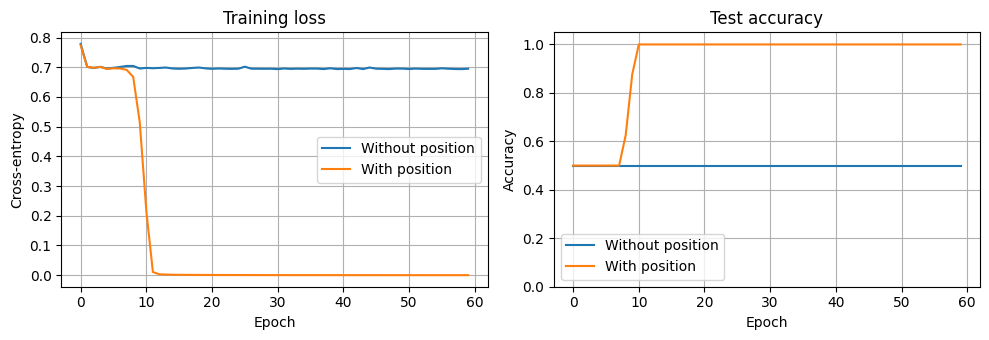

In [ ]:
### CS231n_Lec08_review_Attention_and_Transformers



import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(8)
torch.set_num_threads(1)

SEQ_LEN = 8
D_MODEL = 32 # Embedding Dimension
NUM_HEADS = 4 # The number of Attention Head
EPOCHS = 60
BATCH_SIZE = 64

TOKEN_NAMES = {
    0: ".",
    1: "A",
    2: "B",
}



## --------------------------------------------------
## 1. Generate Sequence Classification Data
## --------------------------------------------------

# Very similar to the data generator used in the Lec07 - RNN code
def make_dataset(num_pairs, seed):
    """
In each pair, the events occur at the same location,
with only the order of A and B reversed.

class 0: A appears before B
class 1: B appears before A
    """
    generator = torch.Generator().manual_seed(seed)

    class_zero = torch.zeros(
        num_pairs,
        SEQ_LEN,
        dtype=torch.long,
    )

    '''
    class_one is a new tensor that has the exact same properties
    (size, data type, device) as class_zero,
    with all its elements filled with zeros.
    '''
    class_one = torch.zeros_like(class_zero)

    # difference from Lec07 code: 0 and (SEQ-1) can be abstracted
    for i in range(num_pairs):
        positions = torch.randperm(
            SEQ_LEN,
            generator=generator,
        )[:2]

        first, second = positions.sort().values.tolist()

        # Assign event 1 and event 2 to one distinct frame each in the sequence.
        class_zero[i, first] = 1   # A
        class_zero[i, second] = 2  # B

        class_one[i, first] = 2    # B
        class_one[i, second] = 1   # A

    tokens = torch.cat(
        [class_zero, class_one],
        dim=0,
    )

    labels = torch.cat([
        torch.zeros(num_pairs, dtype=torch.long),
        torch.ones(num_pairs, dtype=torch.long),
    ])

    assert (tokens == 1).sum(dim=1).eq(1).all()
    assert (tokens == 2).sum(dim=1).eq(1).all()

    return tokens, labels


train_tokens, train_labels = make_dataset(
    num_pairs=400,
    seed=1,
)

test_tokens, test_labels = make_dataset(
    num_pairs=200,
    seed=2,
)

print("Train:", tuple(train_tokens.shape))
print("Test: ", tuple(test_tokens.shape))



## --------------------------------------------------
## 2. Single-layer Transformer Classifier
## --------------------------------------------------
class TinyTransformer(nn.Module):
    def __init__(self, use_position):
        super().__init__()

        self.use_position = use_position

        # Token Embedding: Represents the meaning of a word.
        # token 0: empty position, token 1: A, token 2: B
        self.token_embedding = nn.Embedding(
            num_embeddings=3,
            embedding_dim=D_MODEL,
        )

        self.cls_token = nn.Parameter(
            torch.zeros(1, 1, D_MODEL)
        )

        # Positional Embedding: Represents the postional information of Tokens
        # Second parameter = SEQ_LEN + 1, as it includes the CLS position
        self.position_embedding = nn.Parameter(
            torch.randn(1, SEQ_LEN + 1, D_MODEL) * 0.02
        )

        '''
        Layer normalization: The mean and variance are calculated
        based on the features
        within an individual data sample (a single input instance).
        '''
        self.norm1 = nn.LayerNorm(D_MODEL)

        '''
        Multi-head attention: A core mechanism that performs
        multiple attention operations in parallel.
        '''
        self.attention = nn.MultiheadAttention(
            embed_dim=D_MODEL,
            num_heads=NUM_HEADS,
            dropout=0.0,
            batch_first=True,
        )

        self.norm2 = nn.LayerNorm(D_MODEL)

        # Feedforward Networks: Unidirectional Information Flow Is Key.
        self.feed_forward = nn.Sequential(
            nn.Linear(D_MODEL, 2 * D_MODEL),
            nn.GELU(),
            nn.Linear(2 * D_MODEL, D_MODEL),
        )

        self.final_norm = nn.LayerNorm(D_MODEL)
        self.classifier = nn.Linear(D_MODEL, 2)

    def forward(self, tokens, return_attention=False):
        batch_size = tokens.size(0)

        embedded = self.token_embedding(tokens)

        cls = self.cls_token.expand(
            batch_size,
            -1,
            -1,
        )

        x = torch.cat(
            [cls, embedded],
            dim=1,
        )

        if self.use_position:
            x = x + self.position_embedding

        normalized = self.norm1(x)

        attention_output, attention_weights = self.attention(
            normalized,
            normalized,
            normalized,
            need_weights=return_attention,
            average_attn_weights=False,
        )

        x = x + attention_output
        x = x + self.feed_forward(self.norm2(x))

        cls_output = self.final_norm(x[:, 0])
        scores = self.classifier(cls_output)

        if return_attention:
            return scores, x, attention_weights

        return scores



## --------------------------------------------------
## 3. Model Training
## --------------------------------------------------
def train_model(use_position):
    # Set the initial conditions for both experiments as identical as possible
    torch.manual_seed(20)

    model = TinyTransformer(use_position)

    loader = DataLoader(
        TensorDataset(train_tokens, train_labels),
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(30),
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.003,
    )

    criterion = nn.CrossEntropyLoss()
    loss_history = []
    accuracy_history = []

    for epoch in range(EPOCHS):
        model.train()
        total_loss = 0.0

        for batch_tokens, batch_labels in loader:
            scores = model(batch_tokens)
            loss = criterion(scores, batch_labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += (
                loss.item() * batch_tokens.size(0)
            )

        model.eval()

        with torch.no_grad():
            test_scores = model(test_tokens)

            test_accuracy = (
                test_scores.argmax(dim=1) == test_labels
            ).float().mean().item()

        loss_history.append(
            total_loss / len(loader.dataset)
        )

        accuracy_history.append(test_accuracy)

    return {
        "model": model,
        "loss": loss_history,
        "accuracy": accuracy_history,
    }


without_position = train_model(use_position=False)
with_position = train_model(use_position=True)

for name, result in (
    ("Without position", without_position),
    ("With position", with_position),
):
    print(
        f"{name:16s} | "
        f"test accuracy={result['accuracy'][-1]:.3f} | "
        f"final loss={result['loss'][-1]:.3f}"
    )



## --------------------------------------------------
## 4. Compare output for reversed-order pairs
## --------------------------------------------------
num_test_pairs = len(test_tokens) // 2

pair = test_tokens[
    [0, num_test_pairs]
]

no_pos_model = without_position["model"]
pos_model = with_position["model"]

with torch.no_grad():
    no_pos_scores = no_pos_model(pair)
    pos_scores = pos_model(pair)

'''
# In the absence of positional information, the outputs for
two inputs that differ only in their order must be identical.
'''
assert torch.allclose(
    no_pos_scores[0],
    no_pos_scores[1],
    atol=1e-5,
)

for i in range(2):
    sequence = " ".join(
        TOKEN_NAMES[token.item()]
        for token in pair[i]
    )

    print(
        sequence,
        "| no-pos:",
        no_pos_scores[i].argmax().item(),
        "| position:",
        pos_scores[i].argmax().item(),
    )



## --------------------------------------------------
## 5. Verificate tensor shapes and attention weights
## --------------------------------------------------
example = test_tokens[:8]

with torch.no_grad():
    scores, hidden, weights = pos_model(
        example,
        return_attention=True,
    )

print("\n[Transformer tensor shapes]")
print("Input tokens:     ", tuple(example.shape))
print("Hidden sequence:  ", tuple(hidden.shape)) # a sequence length = 8 + 1 = 9
print("Attention weights:", tuple(weights.shape))
print("Scores:           ", tuple(scores.shape))

assert hidden.shape == (
    8,
    SEQ_LEN + 1,
    D_MODEL,
)

assert weights.shape == (
    8,
    NUM_HEADS,
    SEQ_LEN + 1,
    SEQ_LEN + 1,
)

assert scores.shape == (8, 2)

# Important: The sum of the probabilities assigned by each query to all keys is 1
assert torch.allclose(
    weights.sum(dim=-1),
    torch.ones_like(weights.sum(dim=-1)),
    atol=1e-5,
)

assert torch.isfinite(scores).all()



## --------------------------------------------------
## 6. Visualization of Learning Results
## --------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

axes[0].plot(
    without_position["loss"],
    label="Without position",
)

axes[0].plot(
    with_position["loss"],
    label="With position",
)

axes[0].set_title("Training loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy")
axes[0].grid(True)
axes[0].legend()

axes[1].plot(
    without_position["accuracy"],
    label="Without position",
)

axes[1].plot(
    with_position["accuracy"],
    label="With position",
)

axes[1].set_title("Test accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0.0, 1.05)
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()

# CS231n_Lec08_review_Attention_and_Transformers
## Further Experiment & Review Question Session

### Further Experiment

---

※ original result:
  
Train: (800, 8)  

Test:  (400, 8)  

Without position | test accuracy=0.500 | final loss=0.695  

With position    | test accuracy=1.000 | final loss=0.000  

A . . . B . . . | no-pos: 0 | position: 0  

B . . . A . . . | no-pos: 0 | position: 1

[Transformer tensor shapes]  

Input tokens:      (8, 8)  

Hidden sequence:   (8, 9, 32)  

Attention weights: (8, 4, 9, 9)  

Scores:            (8, 2)
  
  
  

---
### E1. What if we change NUM_HEADS from 4 to 1? Is a multi-head structure truly necessary for this simple problem?

→ E1 result:
  
Train: (800, 8)  

Test:  (400, 8)
  
Without position | test accuracy=0.500 | final loss=0.695
  
With position    | test accuracy=1.000 | final loss=0.000
  
A . . . B . . . | no-pos: 0 | position: 0
  
B . . . A . . . | no-pos: 0 | position: 1

  
[Transformer tensor shapes]
  
Input tokens:      (8, 8)  

Hidden sequence:   (8, 9, 32)  

Attention weights: (8, 1, 9, 9)  

Scores:            (8, 2)

→  No, a multi-head structure is not strictly necessary for this simple task. In this practical example, both the multi-head (NUM_HEAD = 4) and single-head (NUM_HEAD = 1) models achieved identical test accuracy (1.000) and loss (0.000). In other words, for simple problems like the one in the exercise above, single-head attention is sufficient to perform the task.  

(One idea: This highlights the important trade-off between problem complexity and resource efficiency. While multi-head attention is essential for capturing diverse relationships in complex, large-scale real-world data, using it on overly simple tasks only adds unnecessary memory and computational overhead without improving performance.)

(정답은 '아니다.' 이 간단한 실습 코드에서는, NUM_HEAD가 4인 멀티 헤드 어텐션이나 NUM_HEAD가 1인 단일 헤드 어텐션 모델 모두 동일한 테스트 성능(1.000)과 손실(0.000)을 보였다. 즉, 위 실습과 같은 단순한 문제의 경우, 단일 헤드 어텐션으로 충분히 작업을 수행할 수 있다.)

(추가 실험이 필요한 해석: 문제 복잡도와 자원 효율성 간 상관관계로 생각을 넓힐 수 있다. 모델이 해결해야 하는 문제 상황 또는 범위가 주어질 때, 단순히 모델이 데이터를 처리할 수 있는지뿐만 아니라 모델이 필요한 자원(기억/연산) 필요치가 어떠한지도 확인해야 한다. 이 실습 코드는 단순했기에 NUM_HEAD = 1일 때도 잘 작동했다. 그러나 실제 현장에서 크기와 복잡도가 매우 큰 데이터 & 작업을 다룰 때는 하드웨어 효율성에 대해서도 고민해야 할 것이다.)

  
  ### E2. What if we change positional signal like that?  
  → x = x + 0.01 * self.position_embedding
  ### How do the convergence speed and accuracy change when the position signal becomes smaller?  

→ E2 result:  
Train: (800, 8)  

Test:  (400, 8)  

Without position | test accuracy=0.500 | final loss=0.695  

With position    | test accuracy=0.500 | final loss=0.695  

A . . . B . . . | no-pos: 0 | position: 0  

B . . . A . . . | no-pos: 0 | position: 0  


[Transformer tensor shapes]  

Input tokens:      (8, 8)  

Hidden sequence:   (8, 9, 32)  

Attention weights: (8, 4, 9, 9)  

Scores:            (8, 2)


→  When the positional signal is scaled down to 0.01, the transformer model’s behavior becomes nearly identical to what it would be without any positional embeddings. During training, the convergence fails to reach the optimal loss, and test accuracy plummeted by approximately 50%, dropping from 1.000 to 0.500. This demonstrates the necessity of positional embeddings within the attention mechanism. The attention mechanism, by itself, has no inherent way of knowing the positions of tokens; consequently, it treats two inputs containing the same tokens as identical, regardless of their order. This leads to critical errors—especially in tasks where sequence is paramount—and these test results serve as a clear illustration of such a failure.  
(위치 신호가 0.01배로 감소할 때, 트랜스포머 모델은 위치 임베딩이 없는 상태와 결과가 같아진다. 훈련 결과 안정적인 수렴에 실패했고, 테스트 성능이 1.000에서 0.5로 50% 급락했다. 이는 어텐션 메커니즘에서 위치 임베딩(정보)의 필요성을 보여준다. 어텐션 메커니즘은 자체적으로 토큰 위치 정보를 알 수 없다. 따라서 순서가 달라도 같은 토큰을 지닌 두 입력을 동일한 객체로 바라본다. 특히 순서가 중요한 작업에서는 치명적인 오류가 발생하고, 이 테스트 결과는 작은 사례인 셈이다.)


### Review Question  
Q1 - Why does a Transformer model without positional embedding produce the same logits for pairs that have the same counts of A and B, regardless of their order?

→ This is due to the permutation equivariance nature of a Transformer without positional embeddings. Without positional cues, the self-attention mechanism treats sequences containing the same tokens in different orders identically, leading to the exact same output logits. This highlights the importance of positional embeddings, as a Transformer cannot inherently capture token order on its own and may produce incorrect outputs on order-sensitive tasks.
  
(위치 임베딩이 없는 트랜스포머의 순열 등변성 때문이다. 위치 정보(신호)가 없다면, 셀프 어텐션 메커니즘은 서로 다른 순서로 동일한 토큰을 지닌 시퀀스를 같은 객체로 취급한다. 이 결과는 위치 임베딩의 중요성을 보여준다; 위치 임베딩이 없다면 트랜스포머 모델은 순서에 민감한 작업에 대해 부정확한 결과를 출력할 위험이 있다.)

Q2 - Why should softmax(dim=-1) be applied when the attention score shape is (batch, heads, query, key)?

  → This is to ensure that the sum of the attention weights for all keys—relative to a single query—equals 1 (100%). Raw attention scores quantify the degree of relevance between a given query vector and all available key vectors. To use these scores as weights for taking a weighted sum of the value vectors, they must be normalized into a probability distribution across all keys for each query. Since dim=-1 refers to the final dimension, in the shape (batch, heads, query, key), it applies the softmax function along the key axis.

  (한 쿼리에 대한 모든 key 확률값이 1(100%)이 되는지 확인하기 위해서이다.  소프트맥스를 적용한 어텐션 스코어는, 각 쿼리 벡터 요소가 전체 키 벡터와 얼마나 연관성이 있는지를 수치화한다. 즉 한 쿼리에 대한 모든 키 벡터 연관성을 합치면 100%가 나와야 한다. 따라서 키 벡터를 축으로 소프트맥스를 적용해야 한다. dim(-1)은 마지막 인수를 가리키므로, 이 shape에서 키 벡터를 의미한다.)